<div align="center" style="padding:40px 24px;background:linear-gradient(135deg,#0e1a2e 0%,#13223b 100%);border-radius:14px;border-bottom:5px solid #ffd43b;">
  <p style="margin:0;color:#6aaef0;font-family:monospace;font-weight:700;font-size:14px;letter-spacing:.16em;text-transform:uppercase;">The AI Learning Hub · Lesson 03 · Applied AI: unstructured data</p>
  <h1 style="margin:14px 0 6px;color:#f1f5fb;font-size:42px;">🎮 Challenge 2 · YOLO Scavenger Hunt</h1>
  <p style="margin:0;color:#b4c2d8;font-size:18px;">How many objects can YOLO find on your desk in 60 seconds?</p>
</div>

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/the-ai-learning-hub/03-applied-ai-projects/blob/main/02_computer_vision/03_challenge_yolo/Challenge_2_YOLO_Scavenger_Hunt.ipynb) [![Slides](https://img.shields.io/badge/slides-Lesson_03-ffd43b)](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#challenge-2)

In notebook 04 our model looked at a whole photo and gave **one answer**: *cat* or *dog*. Real cameras (phones, cars, shop tills) need more: **what** is in the picture, **where**, and **how many**. That is **object detection**, and the most famous family of detectors is **YOLO** (*You Only Look Once*). Today it runs **live on your webcam**, on a normal laptop CPU, and you play against the clock.

## 🎯 Objectives
By the end of this challenge you will be able to:
- explain in plain words the difference between **classification** (notebook 04) and **detection** (boxes + labels + confidence);
- run a pretrained detector (YOLO26 nano) on a live video and read its **frames per second** on a CPU;
- see how the **confidence threshold** and a "seen in 3 frames in a row" rule trade missed objects against false alarms;
- find what a detector cannot know (only 80 classes) and how it can be fooled.

**📋 Prerequisites:** notebook [04 · Cats vs dogs](../02_project_cats_vs_dogs/04_Cats_vs_Dogs_And_Our_Pets.ipynb) · **▶️ How to use:** run all cells once (it plays on the example photos), then set `LIVE = True` in the ✏️ **YOUR TURN** cell and re-run from there. You play alone, on your own laptop.

## 🎮 How to play

> **The hunt** 🔎 A window opens with your webcam. You have **60 seconds** to show YOLO as many objects as you can, especially the ones on the **hunt list**: `cup` · `bottle` · `cell phone` · `book` · `scissors` · `keyboard` · `mouse` · `laptop` · `backpack` · `potted plant`.
> An object counts when YOLO sees it with confidence **≥ 0.35** in **3 frames in a row** (one lucky frame is not enough). Each found item gets ticked `[x]` on the screen, with the second you found it, and a snapshot is kept for your gallery. Press **Q** to stop early.
>
> **Fool YOLO** 🎭 Make YOLO "see" something that is **not really there**: a drawing of a cup, a photo of a dog on your phone screen, a reflection, a toy… Then declare it in the `FOOLED` list (honesty rule: only things that are not really there).
>
> | Rule | Points |
> |---|---|
> | each **different** object class YOLO confirms (person, cup, chair…) | **+1** |
> | each **hunt-list** item found (on top of the +1) | **+3** |
> | each **Fool YOLO** claim that YOLO really detected (max 3) | **+5** |
>
> **Medals:** 🥉 Bronze ≥ 10 · 🥈 Silver ≥ 25 · 🥇 Gold ≥ 40 points.
>
> **No webcam, or in Colab?** Photo mode: take photos with your phone (desk, room, bag), put them in [`my_photos/`](my_photos/) (or take/upload them in Colab with the cell of section 3). Same rules, each photo counts as a short video. The notebook ships with **3 example photos** so it always runs: they are worth a Bronze. **Beat them!**

## 📑 Contents
1. [🧠 Classification vs detection](#sec-1)
2. [✏️ YOUR TURN · game settings](#sec-2)
3. [🎥 Play!](#sec-3)
4. [📸 Your gallery](#sec-4)
5. [🏆 Your scorecard](#sec-5)
6. [🧠 What did we learn?](#sec-6)
7. [📌 Summary](#sec-7)
8. [📚 Learn more](#sec-8)

<a id="sec-0"></a>
## ⚙️ Setup
Uses the `ultralytics` package (installed with the project; Colab installs it here). The model weights (≈ 5 MB) download once into `data/_cache/yolo/`.

In [1]:
# ⚙️ Setup: works locally (VS Code / Jupyter) and in Google Colab
import os
import subprocess
import sys
import warnings
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    ROOT = Path("/content/03-applied-ai-projects")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/the-ai-learning-hub/03-applied-ai-projects.git", str(ROOT)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)
    os.chdir(ROOT)
else:  # locally: walk up until we find the folder that has src/ and data/
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir() and (p / "data").is_dir())
sys.path.insert(0, str(ROOT))

# Quieter output: no download bars or library chatter
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
warnings.filterwarnings("ignore")
os.environ.setdefault("YOLO_VERBOSE", "False")   # no ultralytics chatter (set before importing it)
print("Project root:", ROOT.name, "(Colab)" if IN_COLAB else "(local)")

Project root: 03-applied-ai-projects (local)


In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as IPyImage
from IPython.display import display
from matplotlib.patches import Rectangle
from ultralytics import YOLO

from src import challenges as ch
from src.paths import cache_dir
from src.plotting import PALETTE, apply_style
from src.vision import list_images, load_image

apply_style()
SEED = 42
np.random.seed(SEED)
PHOTOS = ROOT / "02_computer_vision" / "03_challenge_yolo" / "my_photos"

# Only the authors use this (EXPORT_SLIDES=1) to refresh the images in the slide deck.
EXPORT_SLIDES = os.environ.get("EXPORT_SLIDES") == "1"
def save_slide(fig, name):
    if EXPORT_SLIDES:
        from src.vision import save_slide_image
        save_slide_image(fig, ROOT / "assets" / "slides" / name)


def show_photos(fig):
    """Show a figure full of photos as a JPEG (keeps the notebook light) instead of a heavy PNG."""
    import io
    buf = io.BytesIO()
    fig.savefig(buf, format="jpg", dpi=80, pil_kwargs={"quality": 82})
    plt.close(fig)
    display(IPyImage(buf.getvalue()))

print(f"Ready · photos folder: {PHOTOS.relative_to(ROOT)} ({len(list_images(PHOTOS))} photos)")

Ready · photos folder: 02_computer_vision\03_challenge_yolo\my_photos (3 photos)


<a id="sec-1"></a>
# 1. 🧠 Classification vs detection

> 🧠 **How it works, in plain words**
> - **Classification** (notebook 04): one photo in → **one label** out (*"dog, 97%"*). It does not say where the dog is, or that there is also a plant.
> - **Detection**: one photo in → a **list of objects**, each with a **box** (where), a **class** (what) and a **confidence** (how sure).
> - **YOLO** (*You Only Look Once*, Redmon et al. 2016) looks at the whole image **once**: a CNN like the ones of notebooks 03–04 cuts the image into a grid, and every grid cell proposes boxes and classes at the same time. One pass = fast enough for live video.
> - **Analogy:** classification is a person who glances at a photo and says *"it's a kitchen"*; detection is a person who points at each thing and says *"cup here, bottle there, laptop there"*.
> - **Limits:** it only knows the **80 classes** of the COCO dataset it was trained on (no *pen*, no *stapler*, no *glasses*), small or hidden objects are hard, and it only sees pixels.

> 📖 **Mini-glossary**
> - **Bounding box:** the rectangle around an object, 4 numbers (x1, y1, x2, y2) in pixels.
> - **Confidence:** the model's score for a box (0–1). We keep boxes above a **threshold**, the same idea as the threshold of Lesson 02.
> - **COCO:** *Common Objects in Context*, 118,000 training photos with 80 everyday classes. YOLO learned from it.
> - **FPS:** frames per second: how many images the model can process each second. Video feels smooth above ~10–15.

We use **YOLO26n** (Ultralytics, January 2026), the *nano* version: about 2.4 M parameters, made to run on CPUs and phones.

In [3]:
WEIGHTS = cache_dir() / "yolo" / "yolo26n.pt"      # downloaded once into data/_cache (not into the repository root)
WEIGHTS.parent.mkdir(parents=True, exist_ok=True)
t0 = time.perf_counter()
model = YOLO(str(WEIGHTS))
print(f"YOLO26n loaded in {time.perf_counter() - t0:.1f} s · "
      f"{sum(p.numel() for p in model.model.parameters()) / 1e6:.1f} M parameters · {len(model.names)} classes it knows:")
print(", ".join(model.names.values()))


def detect(frame, conf=0.25, imgsz=640):
    """YOLO on one image (file path, or a BGR array from OpenCV) → [(class, confidence, (x1, y1, x2, y2)), ...]."""
    r = model.predict(frame, conf=conf, imgsz=imgsz, device="cpu", verbose=False)[0]
    return [(r.names[int(c)], float(p), tuple(b.tolist())) for c, p, b in zip(r.boxes.cls, r.boxes.conf, r.boxes.xyxy)]

YOLO26n loaded in 0.1 s · 2.6 M parameters · 80 classes it knows:
person, bicycle, car, motorcycle, airplane, bus, train, truck, boat, traffic light, fire hydrant, stop sign, parking meter, bench, bird, cat, dog, horse, sheep, cow, elephant, bear, zebra, giraffe, backpack, umbrella, handbag, tie, suitcase, frisbee, skis, snowboard, sports ball, kite, baseball bat, baseball glove, skateboard, surfboard, tennis racket, bottle, wine glass, cup, fork, knife, spoon, bowl, banana, apple, sandwich, orange, broccoli, carrot, hot dog, pizza, donut, cake, chair, couch, potted plant, bed, dining table, toilet, tv, laptop, mouse, remote, keyboard, cell phone, microwave, oven, toaster, sink, refrigerator, book, clock, vase, scissors, teddy bear, hair drier, toothbrush


One example photo, what YOLO returns (`results.boxes` holds the boxes, classes and confidences), and the difference with notebook 04 in one picture:

,class,confidence,x1,y1,x2,y2
0,dog,0.91,0,585,463,1022
1,potted plant,0.77,517,284,757,734
2,orange,0.41,251,598,289,628


One photo in 64 ms on this CPU → about 16 images per second


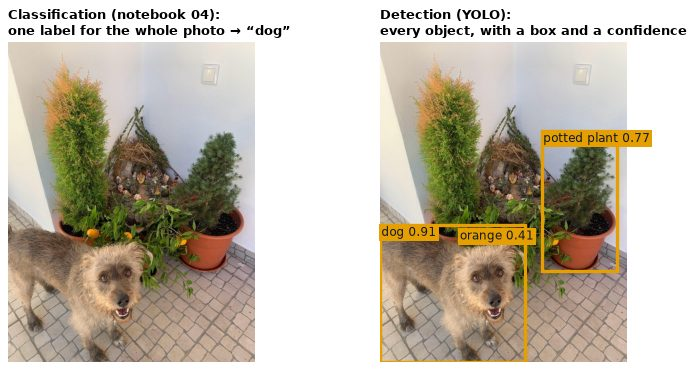

In [4]:
example = PHOTOS / "example_dog_and_plants.jpg"
detect(str(example))                                  # warm-up: the very first prediction is slower
t0 = time.perf_counter()
dets = detect(str(example))
seconds_per_photo = time.perf_counter() - t0
display(pd.DataFrame([(c, round(p, 2), *[round(v) for v in b]) for c, p, b in dets],
                     columns=["class", "confidence", "x1", "y1", "x2", "y2"]))
print(f"One photo in {seconds_per_photo * 1000:.0f} ms on this CPU → about {1 / seconds_per_photo:.0f} images per second")

img = load_image(example)
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
axes[0].imshow(img)
axes[0].set_title("Classification (notebook 04):\none label for the whole photo → “dog”", fontsize=12)
axes[1].imshow(img)
for cls, conf, (x1, y1, x2, y2) in dets:
    if conf >= ch.CH2_RULES["min_confidence"]:
        axes[1].add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, lw=3, ec=PALETTE["orange"]))
        axes[1].text(x1 + 4, y1 + 4, f"{cls} {conf:.2f}", va="top", fontsize=11, color=PALETTE["navy"],
                     bbox=dict(fc=PALETTE["orange"], ec="none", pad=2))
axes[1].set_title("Detection (YOLO):\nevery object, with a box and a confidence", fontsize=12)
for ax in axes:
    ax.axis("off")
show_photos(fig)

👀 **What to notice:** detection finds the **dog** *and* the **potted plants**, each with its own box. The numbers are confidences: YOLO is very sure about the dog and less sure about some plants. Sometimes it is even wrong (look for *orange* on the little fruits), and that is where the confidence threshold matters.

<a id="sec-2"></a>
# 2. ✏️ YOUR TURN · game settings

Change the settings, then run the cells below.
- `LIVE = True` plays with your **webcam** (on your laptop, in Jupyter or VS Code). Leave `False` to play with the photos in `my_photos/` (or in Colab, where Python cannot read the webcam live).
- `DISPLAY = "window"` opens a separate OpenCV window (smoothest; click on it and press **Q** to stop). If a window is awkward (e.g. some VS Code setups), use `"inline"` to watch the video inside the notebook (stop with the ⏹ *Interrupt* button).
- `FOOLED`: your Fool-YOLO claims, as `(where, class)`: `where` is `"webcam"` or a photo file name. Only things that are **not really there** (honesty rule)!

In [5]:
# ✏️ YOUR TURN
LIVE = False                     # 👉 True = play with your webcam (60 s) · False = photos in my_photos/
DISPLAY = "window"               # "window" (OpenCV window, press Q to stop) or "inline" (inside the notebook)
CAMERA_INDEX = 0                 # 0 = built-in webcam; try 1 for an external camera
TIME_LIMIT = ch.CH2_RULES["time_limit"]          # 60 seconds
HUNT_LIST = ch.HUNT_LIST         # or your own list of COCO class names
MIN_CONFIDENCE = ch.CH2_RULES["min_confidence"]  # 0.35: lower = finds more, but more false alarms
MIN_FRAMES = ch.CH2_RULES["min_frames"]          # 3 frames in a row to confirm an object

FOOLED = [                       # Fool YOLO: (where, class YOLO saw but is NOT really there)
    ("example_cats_on_a_screen.jpg", "cat"),     # the cats are only pixels on a (drawn) laptop screen
    ("example_cats_on_a_screen.jpg", "bed"),     # ... and so is the bed
]

# YOLO keeps only boxes above MIN_CONFIDENCE: the threshold you choose is the one the game uses
unknown = [h for h in HUNT_LIST if h not in model.names.values()]
assert not unknown, f"YOLO does not know {unknown}: use names from the list of 80 classes above"

<a id="sec-3"></a>
# 3. 🎥 Play!

**Colab or photo mode only:** this cell lets you take photos with your webcam or upload photos from your phone. Locally, simply copy your photos into the [`my_photos/`](my_photos/) folder.

> 🔒 **Privacy in Colab:** a Colab snapshot or upload is **sent to Google's hosted runtime** and saved there as a JPEG in `my_photos/` (it disappears when the runtime ends; delete it earlier from the 📁 Files panel if you like). Only the **local live mode** keeps your webcam images in your laptop's memory and saves nothing.

In [6]:
TAKE_PHOTOS = 0     # Colab: how many webcam snapshots to take now (e.g. 3); 0 = none
UPLOAD = False      # Colab: True = upload photos from your computer/phone

if IN_COLAB and (TAKE_PHOTOS or UPLOAD):
    from base64 import b64decode

    from google.colab import files
    from google.colab.output import eval_js
    from IPython.display import Javascript

    def take_photo(filename, quality=0.85):
        """Colab webcam snippet: 'Capture' saves one photo, 'Cancel' stops. Returns True if a photo was saved."""
        display(Javascript('''
        async function takePhoto(quality) {
          let stream = null;
          try {
            stream = await navigator.mediaDevices.getUserMedia({video: true});
          } catch (err) {
            return 'ERROR:' + err.name;            // permission denied or no camera
          }
          const div = document.createElement('div');
          try {
            const capture = document.createElement('button');
            capture.textContent = 'Capture';
            const cancel = document.createElement('button');
            cancel.textContent = 'Cancel';
            div.appendChild(capture);
            div.appendChild(cancel);
            const video = document.createElement('video');
            video.style.display = 'block';
            document.body.appendChild(div);
            div.appendChild(video);
            video.srcObject = stream;
            await video.play();
            google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
            const choice = await new Promise((resolve) => {
              capture.onclick = () => resolve('capture');
              cancel.onclick = () => resolve('cancel');
            });
            if (choice === 'cancel') return 'CANCELLED';
            const canvas = document.createElement('canvas');
            canvas.width = video.videoWidth;
            canvas.height = video.videoHeight;
            canvas.getContext('2d').drawImage(video, 0, 0);
            return canvas.toDataURL('image/jpeg', quality);
          } finally {
            stream.getTracks().forEach((track) => track.stop());   // always switch the camera off
            div.remove();
          }
        }'''))
        data = eval_js(f"takePhoto({quality})")
        if not data or data.startswith("ERROR:"):
            print(f"📷 No webcam access ({(data or 'no answer')[6:]}): allow the camera in the browser, or use UPLOAD = True.")
            return False
        if data == "CANCELLED":
            print("📷 Cancelled.")
            return False
        (PHOTOS / filename).write_bytes(b64decode(data.split(",")[1]))
        print("saved", filename)
        return True

    for k in range(TAKE_PHOTOS):
        if not take_photo(f"webcam_{int(time.time())}_{k}.jpg"):
            break
    if UPLOAD:
        uploaded = files.upload() or {}
        if not uploaded:
            print("No file uploaded.")
        for name, content in uploaded.items():
            (PHOTOS / name).write_bytes(content)
            print("saved", name)
else:
    print(f"{len(list_images(PHOTOS))} photos in my_photos/:", ", ".join(p.name for p in list_images(PHOTOS)))

3 photos in my_photos/: example_cat_in_my_bag.jpg, example_cats_on_a_screen.jpg, example_dog_and_plants.jpg


**The game.** With `LIVE = True` a window opens with your webcam: show objects to the camera (or move the laptop around your desk). Boxes appear around everything YOLO recognises (orange = hunt-list item, blue = other object), the checklist is on the left, the timer and the **FPS** at the top right. The camera is always released at the end, even if you stop the cell. Without a camera, the game switches to the photos automatically.

In [7]:
tracker = ch.HuntTracker(HUNT_LIST, min_conf=MIN_CONFIDENCE, min_frames=MIN_FRAMES)
mode = "photos"
if LIVE and IN_COLAB:
    print("📷 In Colab, Python cannot read your webcam live: take snapshots with the cell above. Playing with photos.")
elif LIVE:
    import cv2
    detect(np.zeros((480, 640, 3), np.uint8), imgsz=480)            # warm-up before the clock starts
    display_mode = DISPLAY
    if display_mode == "window":                                     # no screen for windows (e.g. a server)? go inline
        try:
            cv2.namedWindow("YOLO scavenger hunt - press Q to stop")
        except cv2.error:
            print("🪟 OpenCV cannot open a window here: showing the video inside the notebook instead.")
            display_mode = "inline"
    if display_mode == "inline":
        import ipywidgets as widgets
        screen = widgets.Image(format="jpeg", width=720)
        display(screen)

        def show(frame):
            screen.value = cv2.imencode(".jpg", frame, [cv2.IMWRITE_JPEG_QUALITY, 70])[1].tobytes()
            return True
    else:
        def show(frame):
            cv2.imshow("YOLO scavenger hunt - press Q to stop", frame)
            return (cv2.waitKey(1) & 0xFF) not in (ord("q"), 27)         # Q or Esc stops the game
    try:
        game = ch.run_hunt(lambda f: detect(f, conf=MIN_CONFIDENCE, imgsz=480), ch.webcam_frames(CAMERA_INDEX),
                           tracker, time_limit=TIME_LIMIT, display=show)
        if game["frames"] == 0:
            raise RuntimeError("The camera sent no image.")
        mode = "webcam"
    except RuntimeError as err:
        print(f"📷 {err} Playing with the photos in my_photos/ instead.")
        tracker = ch.HuntTracker(HUNT_LIST, min_conf=MIN_CONFIDENCE, min_frames=MIN_FRAMES)
    finally:
        if display_mode == "window":
            try:
                cv2.destroyAllWindows()
                cv2.waitKey(1)
            except cv2.error:
                pass

if mode == "photos":
    photos = list_images(PHOTOS)
    t0 = time.perf_counter()
    game = ch.run_hunt(lambda f: detect(f, conf=MIN_CONFIDENCE), ch.photo_frames(photos, repeats=MIN_FRAMES),
                       tracker, stop_when_done=False)
    speed = f"{len(photos)} photos in {time.perf_counter() - t0:.1f} s"
else:
    speed = f"{game['frames']} frames at {game['fps'] or 0:.1f} FPS on this CPU"
print(f"Mode: {mode} · {speed} · found {len(tracker.seen)} different objects, "
      f"{len(tracker.hunt_found)}/{len(HUNT_LIST)} from the hunt list")

Mode: photos · 3 photos in 0.5 s · found 7 different objects, 2/10 from the hunt list


<a id="sec-4"></a>
# 4. 📸 Your gallery

The snapshots taken the moment each object was confirmed (in local live mode nothing is saved to disk: your webcam images stay in your laptop's memory), then the full frames with all their boxes.

,object,on hunt list,found in,time (s)
0,backpack,True,example_cat_in_my_bag.jpg,0.1
1,bed,False,example_cat_in_my_bag.jpg,0.1
2,cat,False,example_cat_in_my_bag.jpg,0.1
3,suitcase,False,example_cat_in_my_bag.jpg,0.1
4,dog,False,example_dog_and_plants.jpg,0.4
5,orange,False,example_dog_and_plants.jpg,0.4
6,potted plant,True,example_dog_and_plants.jpg,0.4


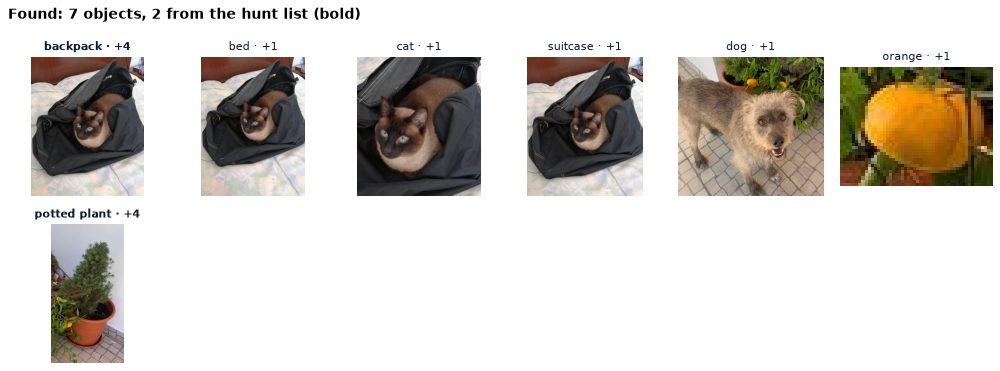

In [8]:
display(tracker.table())
snaps = game["snapshots"]
if snaps:
    cols = min(6, len(snaps))
    rows = int(np.ceil(len(snaps) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(2.1 * cols, 2.35 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (cls, crop) in zip(axes.ravel(), snaps.items()):
        info = tracker.confirmed[cls]
        on_list = cls in HUNT_LIST
        ax.imshow(crop)
        ax.set_title(f"{cls} · +{1 + 3 * on_list}" + (f"\n{info['t']:.0f} s" if mode == "webcam" else ""),
                     fontsize=10, loc="center", fontweight="bold" if on_list else "normal",
                     color=PALETTE["navy"])
    fig.suptitle(f"Found: {len(snaps)} objects, {len(tracker.hunt_found)} from the hunt list (bold)",
                 x=0.01, ha="left", fontsize=13, fontweight="bold")
    fig.tight_layout()
    show_photos(fig)

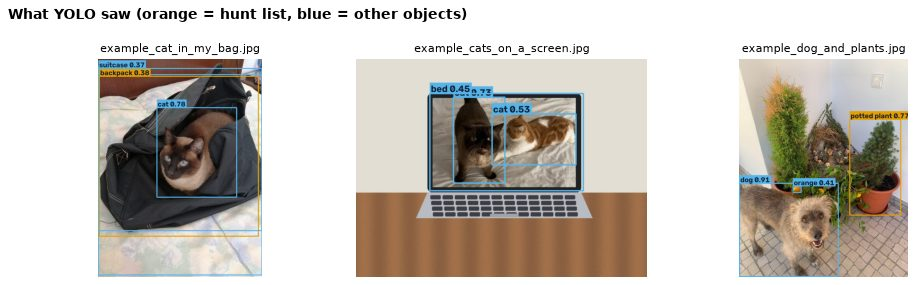

In [9]:
frames = list(game["last_frames"].items())
cols = min(3, len(frames))
fig, axes = plt.subplots(int(np.ceil(len(frames) / cols)), cols, figsize=(4.2 * cols, 3.6 * np.ceil(len(frames) / cols)),
                         squeeze=False)
for ax in axes.ravel():
    ax.axis("off")
for ax, (source, frame) in zip(axes.ravel(), frames):
    ax.imshow(frame)
    ax.set_title(source, fontsize=10, loc="center", fontweight="normal")
fig.suptitle("What YOLO saw (orange = hunt list, blue = other objects)", x=0.01, ha="left", fontsize=13,
             fontweight="bold")
fig.tight_layout()
save_slide(fig, "ch2-gallery.webp")
show_photos(fig)

<a id="sec-5"></a>
# 5. 🏆 Your scorecard

✅ hunt list found:   backpack, potted plant
❌ still missing:     cup, bottle, cell phone, book, scissors, keyboard, mouse, laptop
🎭 Fool YOLO accepted: cat (example_cats_on_a_screen.jpg), bed (example_cats_on_a_screen.jpg)


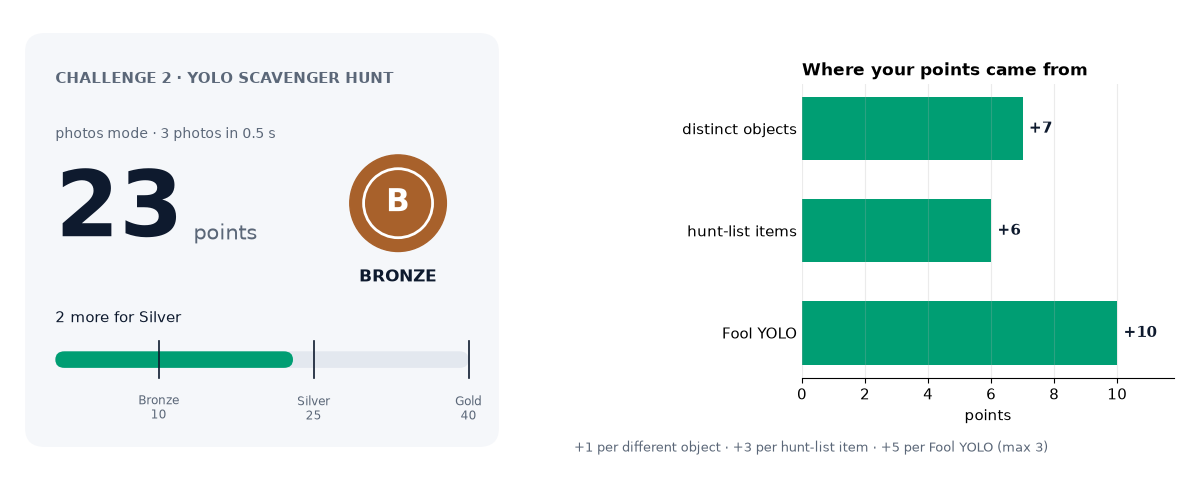

🥉 Bronze: 23 points. 2 more for Silver!


In [10]:
result = ch.hunt_score(tracker.detections_by_source(), HUNT_LIST, fooled=FOOLED)
total = result["total"]
medal, nxt, missing = ch.medal_for(total, ch.LEVELS["yolo_hunt"])
print("✅ hunt list found:  ", ", ".join(result["hunt_found"]) or "nothing yet")
print("❌ still missing:    ", ", ".join(result["hunt_missing"]) or "nothing, well done!")
print("🎭 Fool YOLO accepted:", ", ".join(f"{c} ({w})" for w, c in result["fools_valid"]) or "none")
if result["fools_invalid"]:
    print("   not accepted (YOLO did not confirm it there, or more than 3):",
          ", ".join(f"{c} ({w})" for w, c in result["fools_invalid"]))
fig = ch.plot_scorecard(total, result["breakdown"], ch.LEVELS["yolo_hunt"], "Challenge 2 · YOLO scavenger hunt",
                        subtitle=f"{mode} mode · {speed}", accent=PALETTE["green"],
                        footnote="+1 per different object · +3 per hunt-list item · +5 per Fool YOLO (max 3)")
save_slide(fig, "ch2-scorecard.png")
plt.show()
print(f"{ch.MEDAL_EMOJI[medal]} {medal}: {total} points." + (f" {missing} more for {nxt}!" if nxt else " Top level!"))

<a id="sec-6"></a>
# 6. 🧠 What did we learn?

| What happened in the game | The idea behind it | Back to |
|---|---|---|
| YOLO named **every** object, with a box | **detection** = many (box, class, confidence) per image; **classification** = one label per image | notebook 04 |
| Your *pen*, *glasses* or *charger* never showed up | a model only knows the classes of its training data (80 COCO classes) | Lesson 02 · data defines the task |
| Objects flickered on and off | each frame is a new prediction; the **threshold** and the **3-frames rule** trade missed objects (recall) against false alarms (precision) | Lesson 02 · threshold tuning |
| It saw a cat on a **screen** (or in a drawing) | the model only sees **pixels**; a photo of a cat *is* a cat for it (remember the AI-generated dog of notebook 04) | notebook 04 · Grad-CAM, AI dog |
| ≈ 15–25 **FPS** on a laptop CPU | a *nano* model (2.4 M parameters) + one pass per image; a GPU runs the bigger, more accurate versions in real time | notebook 04 · CPU vs GPU race |

## 💬 Discussion
1. A self-driving car uses detection. Would you rather lower or raise the confidence threshold for *person*? What does each error cost?
2. Your Fool-YOLO trick worked. Is that a bug of the model or a limit of what it was asked to learn?
3. In local live mode the game kept your webcam images only in memory, while the Colab snapshot went to a cloud runtime. Why does that difference matter for a real product with a camera?

<details>
<summary>🧑‍🏫 Instructor guide</summary>

1. Lower: missing a pedestrian (false negative) is far worse than braking for a shadow (false positive). Same reasoning as the spam filter and the threshold of Lesson 02: **the cost of each error** chooses the threshold, not the model. Real systems also combine several sensors and frames (our 3-frames rule is a tiny version of that tracking).
2. A limit of the task: COCO labels say "there is a cat in these pixels", never "this cat is real". To tell a real object from a screen or a drawing you need other data (depth, video motion) and other labels. Link to adversarial examples (Challenge 1) and to the AI-generated dog of notebook 04.
3. Privacy and consent: camera images are personal data. Processing on the device (local live mode: nothing leaves the laptop, nothing is saved) is a strong design choice; the Colab path uploads the photo to Google's servers and stores it there for the session. Mention data minimisation and where data is processed (GDPR).
</details>

<a id="sec-7"></a>
# 7. 📌 Summary

| Idea | In one line |
|---|---|
| Classification | One image → one label (notebook 04) |
| Detection | One image → many boxes, each with a class and a confidence |
| YOLO | Looks at the image once (one CNN pass): fast enough for live video on a CPU |
| COCO classes | A detector only knows what it was trained on (80 everyday classes) |
| Threshold + 3 frames | Fewer false alarms, a few more missed objects: a precision/recall trade-off |
| FPS | The speed that matters for video; nano models for CPUs, bigger ones for GPUs |

**✅ Checklist:**
- [ ] I can explain classification vs detection with an example from my desk.
- [ ] I played at least one 60-second round (or photo mode) and found hunt-list items.
- [ ] I tried to fool YOLO and can say why it worked (or not).
- [ ] I know what happens to the results when I change `MIN_CONFIDENCE`.

<a id="sec-8"></a>
# 8. 📚 Learn more

> 📚 **Learn more**
> - Ultralytics docs: [YOLO26](https://docs.ultralytics.com/models/yolo26/) · [Predict mode and the `Results` object](https://docs.ultralytics.com/modes/predict/). ⚖️ **Licence:** the `ultralytics` package and its YOLO weights are under **AGPL-3.0** (free for learning and open-source projects; a commercial product that uses them must either publish its source code or buy an Ultralytics Enterprise licence).
> - Redmon, Divvala, Girshick & Farhadi (2016). [*You Only Look Once: Unified, Real-Time Object Detection*](https://arxiv.org/abs/1506.02640), the original YOLO paper.
> - Lin et al. (2014). [*Microsoft COCO: Common Objects in Context*](https://cocodataset.org/), the dataset behind the 80 classes.
> - Thys, Van Ranst & Goedemé (2019). [*Fooling automated surveillance cameras: adversarial patches to attack person detection*](https://arxiv.org/abs/1904.08653): a printed patch that makes people invisible to YOLO.

---
<div align="center">

⬅️ [Previous: 04 · Cats vs dogs, and our pets](../02_project_cats_vs_dogs/04_Cats_vs_Dogs_And_Our_Pets.ipynb) &nbsp;·&nbsp; 🏠 [Lesson 03](../../README.md) &nbsp;·&nbsp; [Next: 05 · Everything is a vector](../../03_multimodal/01_project_everything_is_a_vector/05_Everything_Is_A_Vector.ipynb) ➡️

**The AI Learning Hub** · Lesson 03 — Applied AI: unstructured data<br>
MIT License

</div>